In [ ]:
# %pip install tensorflow tensorflow-datasets matplotlib
# %pip install -q tensorflow tensorflow-datasets matplotlib scikit-learn
# %pip install --no-cache-dir tensorflow-datasets
# %pip install importlib-resources

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

In [7]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names
print(class_names)

['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


In [8]:
IMG_SIZE = 150

def prep(img, label):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = preprocess_input(img)
    label = tf.one_hot(label, 5)
    return img, label

train_ds = train_raw.map(prep).shuffle(1000).batch(32)
val_ds = val_raw.map(prep).batch(32)
test_ds = test_raw.map(prep).batch(32)

In [9]:
base_model = VGG16(weights="imagenet", include_top=False,
                   input_shape=(IMG_SIZE, IMG_SIZE, 3))

In [10]:
base_model.trainable = False

In [11]:
model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(50, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(5, activation="softmax")
])

model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │       409,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,125,463 (57.70 MB)

 Trainable params: 410,775 (1.57 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [12]:
history = model.fit(train_ds, validation_data=val_ds, epochs=1)

c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.6528 - loss: 1.7687 - val_accuracy: 0.7151 - val_loss: 0.8727


In [13]:
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

fine_history = model.fit(train_ds, validation_data=val_ds, epochs=1)

81/81 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.8700 - loss: 0.3986 - val_accuracy: 0.7713 - val_loss: 0.7265


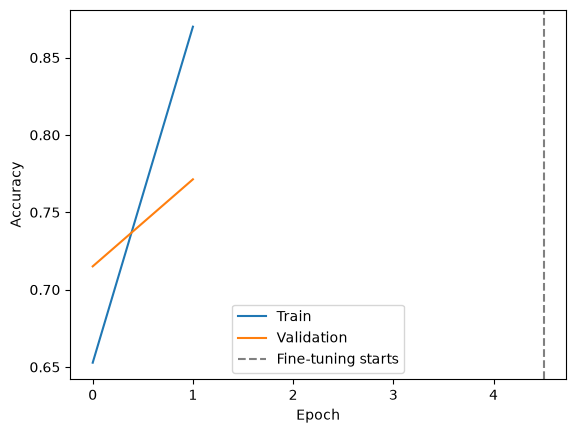

In [14]:
acc = history.history["accuracy"] + fine_history.history["accuracy"]
val_acc = history.history["val_accuracy"] + fine_history.history["val_accuracy"]

plt.plot(acc, label="Train")
plt.plot(val_acc, label="Validation")
plt.axvline(4.5, color="gray", linestyle="--", label="Fine-tuning starts")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [15]:
loss, accuracy = model.evaluate(test_ds)
print("Test accuracy:", round(accuracy * 100, 2), "%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 18s 977ms/step - accuracy: 0.7800 - loss: 0.8043
Test accuracy: 78.0 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


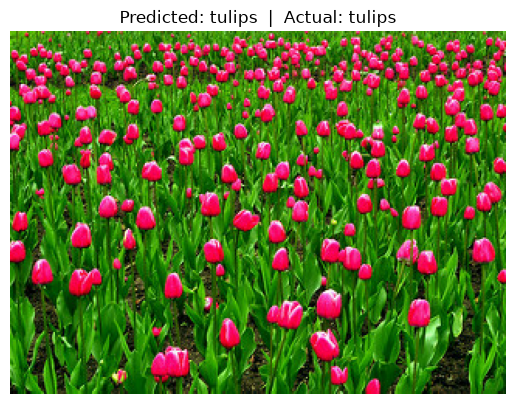

In [18]:
img, label = next(iter(test_raw.skip(10).take(1)))

x, _ = prep(img, label)
pred = model.predict(tf.expand_dims(x, 0))

plt.imshow(img.numpy())
plt.title(f"Predicted: {class_names[np.argmax(pred)]}  |  Actual: {class_names[int(label)]}")
plt.axis("off")
plt.show()